# Trabalho do Grau B (TGB) — Processamento de Imagens de Drones
**Disciplina:** Simulação e Modelagem de Sistemas (Ciência da Computação — Unisinos)  
**Integrantes:** Leandro Istan, Vasco Graveto e Vinícius Müller

Este caderno reúne de forma autocontida todo o estudo de simulação da plataforma web de processamento fotogramétrico de imagens de drones:
1. **Preparação do ambiente** (compatível com Google Colab e execução local no VS Code/Jupyter).
2. **Parâmetros e distribuições de entrada** calibrados com benchmark real (PIX4Dmatic / Puget Systems).
3. **Modelo de simulação em `SimPy`** (validação em CPU com decisão probabilística de reenvio, roteamento condicional por `num_imagens`, alinhamento e geração paralela de ortomosaico + modelo de elevação com junção, e processo `monitor`).
4. **Experimentação estatística:** comparação entre o **Cenário Atual** (2 + 3 servidores) e o **Cenário Servidor Extra** (2 + 4 servidores), com **30 replicações** usando números aleatórios comuns e **Intervalo de Confiança de 95%** ($t$ de Student).
5. **Gráficos de resultados** (evolução temporal da fila em degraus, comparação de cenários com barras de erro do IC de 95%, curva acumulada do *lead time* e ocupação dos servidores).
6. **Demonstração visual (`FuncAnimation`)** exportada diretamente em vídeo **MP4** (`animacao_modelo.mp4`).

In [1]:
# Preparação do ambiente: instala simpy e imageio-ffmpeg automaticamente caso não estejam presentes (ex.: Google Colab)
import importlib.util
import subprocess
import sys

for pacote, modulo in [("simpy", "simpy"), ("imageio-ffmpeg", "imageio_ffmpeg")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", pacote], check=True)

import base64
import csv
from dataclasses import dataclass, field
import os
import shutil

from IPython.display import HTML, display
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import Circle, FancyBboxPatch, Patch, Polygon
import numpy as np
import simpy

print(f"Ambiente pronto! SimPy {simpy.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Ambiente pronto! SimPy 4.1.2 | NumPy 2.5.4 | Matplotlib 3.11.2


## 1. Parâmetros e Distribuições de Entrada

Unidade de tempo da simulação: **minutos** (o instante `0` corresponde às **17h00**, início da janela de pico de retorno das equipes de campo).

In [2]:
# ---------------------------------------------------------------------------
# Parâmetros do modelo (seção 4.2 do modelo conceitual)
# ---------------------------------------------------------------------------

HORA_INICIO = 17                  # hora do relógio que corresponde ao instante 0 (17h00)

MAPAS_POR_NOITE_MEDIA = 100       # Poisson, mapas/noite

ENVIO_MIN = 0.0                   # Triangular do horário de envio, em minutos após as 17h
ENVIO_MODA = 90.0                 # 18h30
ENVIO_MAX = 240.0                 # 21h00

IMAGENS_MIN = 20                  # Triangular de num_imagens por voo
IMAGENS_MODA = 80
IMAGENS_MAX = 200
LIMITE_ROTA = 80                  # Decisão condicional: acima disso, vai para servidores de voos grandes

VALIDACAO_MIN_S = 5.0             # Uniform, segundos (validação em CPU)
VALIDACAO_MAX_S = 15.0
PROB_FALTA_ARQUIVOS = 0.05        # Decisão probabilística: Bernoulli (5% por tentativa de validação)
CORRECAO_MIN = 1.0                # Uniform, minutos (atraso de correção pelo prestador)
CORRECAO_MAX = 3.0

# Tempos por imagem (s/imagem), benchmark Puget Systems / PIX4Dmatic, ±20%
ALINHAMENTO_S_IMG = (0.69, 1.03)
ELEVACAO_S_IMG = (1.22, 1.84)
ORTOMOSAICO_S_IMG = (0.15, 0.23)

CAPACIDADE_CPU = 1
META_LEAD_TIME = 10.0             # Meta de SLA do lead time: até 10 minutos
INTERVALO_MONITOR = 0.5           # Amostragem do estado do sistema a cada 0,5 min

SEMENTE_REFERENCIA = 2026
N_REPLICACOES = 30
SEMENTE_BASE = 1000
SEMENTES = [SEMENTE_BASE + i for i in range(N_REPLICACOES)]

# Cenários comparados (seção 4.3)
CENARIOS = {
    "Atual": {"servidores_pequenos": 2, "servidores_grandes": 3},
    "Servidor extra": {"servidores_pequenos": 2, "servidores_grandes": 4},
}

PASTA_RESULTADOS = "resultados"
PASTA_GRAFICOS = os.path.join(PASTA_RESULTADOS, "graficos")

## 2. Implementação do Modelo de Simulação (`SimPy`)

* **Entidade (`Mapa`):** carrega o atributo `num_imagens`, a `rota` (`"pequenos"` ou `"grandes"`), o número de `tentativas` na validação, `instante_entrada`, `instante_saida` e gerador aleatório próprio (`rng`).
* **Fluxo em `processar_mapa`:**
  1. **Validação em CPU (`simpy.Resource`):** sorteia com $5\%$ de probabilidade a falta de arquivos; se faltar, aguarda o atraso de correção pelo prestador e retorna à fila da CPU.
  2. **Alinhamento:** ocupa 1 servidor do grupo correspondente à rota do mapa.
  3. **Duplicação e Junção:** dispara `ortomosaico` e `elevacao` como processos paralelos independentes que disputam a fila única FIFO do grupo e aguarda ambos terminarem (`yield ortomosaico & elevacao`).

In [3]:
@dataclass
class Mapa:
    id: int
    num_imagens: int
    rota: str
    instante_entrada: float
    rng: np.random.Generator
    tentativas: int = 0
    instante_saida: float = None

    @property
    def lead_time(self):
        return self.instante_saida - self.instante_entrada


@dataclass
class Estatisticas:
    mapas: list = field(default_factory=list)
    tempo_ocupado: dict = field(default_factory=lambda: {"pequenos": 0.0, "grandes": 0.0, "cpu": 0.0})
    concluidos: int = 0
    amostras: list = field(default_factory=list)


def tempo_etapa(mapa, faixa_s_img):
    """Tempo de uma etapa de processamento, em minutos."""
    return mapa.num_imagens * mapa.rng.uniform(*faixa_s_img) / 60.0


def tarefa_servidor(ambiente, servidores, mapa, faixa_s_img, estatisticas):
    """Ocupa um servidor do grupo do mapa pela duração de uma etapa."""
    grupo = servidores[mapa.rota]
    duracao = tempo_etapa(mapa, faixa_s_img)
    with grupo.request() as pedido:
        yield pedido
        yield ambiente.timeout(duracao)
    estatisticas.tempo_ocupado[mapa.rota] += duracao


def processar_mapa(ambiente, cpu, servidores, mapa, estatisticas):
    # 1. Validação em CPU, repetida até não faltar arquivo (decisão por probabilidade)
    while True:
        duracao = mapa.rng.uniform(VALIDACAO_MIN_S, VALIDACAO_MAX_S) / 60.0
        with cpu.request() as pedido:
            yield pedido
            yield ambiente.timeout(duracao)
        estatisticas.tempo_ocupado["cpu"] += duracao
        mapa.tentativas += 1

        if mapa.rng.random() >= PROB_FALTA_ARQUIVOS:
            break
        # O prestador corrige e envia os faltantes: atraso sem fila
        yield ambiente.timeout(mapa.rng.uniform(CORRECAO_MIN, CORRECAO_MAX))

    # 2. Alinhamento, no grupo de servidores definido pela rota (decisão por condição)
    yield ambiente.process(tarefa_servidor(ambiente, servidores, mapa, ALINHAMENTO_S_IMG, estatisticas))

    # 3. Duplicação: ortomosaico e modelo de elevação em paralelo, com junção
    ortomosaico = ambiente.process(tarefa_servidor(ambiente, servidores, mapa, ORTOMOSAICO_S_IMG, estatisticas))
    elevacao = ambiente.process(tarefa_servidor(ambiente, servidores, mapa, ELEVACAO_S_IMG, estatisticas))
    yield ortomosaico & elevacao

    mapa.instante_saida = ambiente.now
    estatisticas.concluidos += 1


def gerar_mapas(semente):
    """Sorteia os mapas da noite com números aleatórios comuns por mapa."""
    rng = np.random.default_rng(semente)
    quantidade = rng.poisson(MAPAS_POR_NOITE_MEDIA)
    envios = np.sort(rng.triangular(ENVIO_MIN, ENVIO_MODA, ENVIO_MAX, size=quantidade))
    imagens = np.rint(rng.triangular(IMAGENS_MIN, IMAGENS_MODA, IMAGENS_MAX, size=quantidade)).astype(int)

    mapas = []
    for i, (envio, n) in enumerate(zip(envios, imagens)):
        rota = "grandes" if n > LIMITE_ROTA else "pequenos"
        mapas.append(Mapa(id=i, num_imagens=int(n), rota=rota, instante_entrada=float(envio),
                          rng=np.random.default_rng([semente, i])))
    return mapas


def chegadas(ambiente, cpu, servidores, mapas, estatisticas):
    for mapa in mapas:
        yield ambiente.timeout(mapa.instante_entrada - ambiente.now)
        estatisticas.mapas.append(mapa)
        ambiente.process(processar_mapa(ambiente, cpu, servidores, mapa, estatisticas))


def monitor(ambiente, cpu, servidores, total_mapas, estatisticas):
    """Amostra o estado do sistema em intervalos regulares, até o último mapa sair."""
    while estatisticas.concluidos < total_mapas:
        estatisticas.amostras.append({
            "tempo": ambiente.now,
            "fila_cpu": len(cpu.queue),
            "fila_pequenos": len(servidores["pequenos"].queue),
            "fila_grandes": len(servidores["grandes"].queue),
            "ocupados_pequenos": servidores["pequenos"].count,
            "ocupados_grandes": servidores["grandes"].count,
            "concluidos": estatisticas.concluidos,
        })
        yield ambiente.timeout(INTERVALO_MONITOR)


def executar_simulacao(cenario, semente):
    """Simula uma noite de pico no cenário indicado."""
    capacidades = CENARIOS[cenario]
    ambiente = simpy.Environment()
    cpu = simpy.Resource(ambiente, capacity=CAPACIDADE_CPU)
    servidores = {
        "pequenos": simpy.Resource(ambiente, capacity=capacidades["servidores_pequenos"]),
        "grandes": simpy.Resource(ambiente, capacity=capacidades["servidores_grandes"]),
    }
    estatisticas = Estatisticas()
    mapas = gerar_mapas(semente)

    ambiente.process(chegadas(ambiente, cpu, servidores, mapas, estatisticas))
    ambiente.process(monitor(ambiente, cpu, servidores, len(mapas), estatisticas))
    ambiente.run()
    return ambiente, estatisticas, capacidades


def calcular_metricas(ambiente, estatisticas, capacidades):
    mapas = estatisticas.mapas
    lead_times = np.array([m.lead_time for m in mapas])
    fim = ambiente.now
    horizonte_h = fim / 60.0
    fora_prazo = int(np.sum(lead_times > META_LEAD_TIME))
    filas_grandes = [a["fila_grandes"] for a in estatisticas.amostras]

    return {
        "mapas": len(mapas),
        "mapas_grandes": sum(m.rota == "grandes" for m in mapas),
        "mapas_com_reenvio": sum(m.tentativas > 1 for m in mapas),
        "p90_lead_time_min": float(np.percentile(lead_times, 90)),
        "lead_time_medio_min": float(lead_times.mean()),
        "lead_time_maximo_min": float(lead_times.max()),
        "mapas_fora_prazo": fora_prazo,
        "percentual_fora_prazo": fora_prazo / len(mapas),
        "vazao_mapas_h": len(mapas) / horizonte_h,
        "utilizacao_pequenos": estatisticas.tempo_ocupado["pequenos"] / (capacidades["servidores_pequenos"] * fim),
        "utilizacao_grandes": estatisticas.tempo_ocupado["grandes"] / (capacidades["servidores_grandes"] * fim),
        "utilizacao_cpu": estatisticas.tempo_ocupado["cpu"] / (CAPACIDADE_CPU * fim),
        "fila_maxima_grandes": max(filas_grandes, default=0),
        "fim_min": fim,
    }


def formatar_hora(minutos):
    total = int(round(HORA_INICIO * 60 + minutos))
    return f"{total // 60:02d}h{total % 60:02d}"


def imprimir_relatorio(cenario, m):
    print("=" * 56)
    print(f"Cenário: {cenario}")
    print("=" * 56)
    print(f"Mapas na noite:             {m['mapas']} ({m['mapas_grandes']} grandes, "
          f"{m['mapas_com_reenvio']} com reenvio)")
    print(f"Último mapa pronto:         {formatar_hora(m['fim_min'])}")
    print(f"P90 do lead time:           {m['p90_lead_time_min']:.2f} min (meta: até {META_LEAD_TIME:.0f} min)")
    print(f"Lead time médio:            {m['lead_time_medio_min']:.2f} min")
    print(f"Lead time máximo:           {m['lead_time_maximo_min']:.2f} min")
    print(f"Mapas fora do prazo:        {m['mapas_fora_prazo']} mapas ({m['percentual_fora_prazo']:.1%})")
    print(f"Vazão:                      {m['vazao_mapas_h']:.1f} mapas/h")
    print(f"Utilização voos pequenos:   {m['utilizacao_pequenos']:.1%}")
    print(f"Utilização voos grandes:    {m['utilizacao_grandes']:.1%}")
    print(f"Utilização da CPU:          {m['utilizacao_cpu']:.1%}")
    print(f"Fila máxima voos grandes:   {m['fila_maxima_grandes']} tarefas")


for nome_cenario in CENARIOS:
    amb_ref, est_ref, cap_ref = executar_simulacao(nome_cenario, SEMENTE_REFERENCIA)
    imprimir_relatorio(nome_cenario, calcular_metricas(amb_ref, est_ref, cap_ref))
    print()

Cenário: Atual
Mapas na noite:             89 (56 grandes, 6 com reenvio)
Último mapa pronto:         20h44
P90 do lead time:           9.74 min (meta: até 10 min)
Lead time médio:            5.39 min
Lead time máximo:           16.14 min
Mapas fora do prazo:        8 mapas (9.0%)
Vazão:                      23.8 mapas/h
Utilização voos pequenos:   20.0%
Utilização voos grandes:    42.0%
Utilização da CPU:          7.2%
Fila máxima voos grandes:   8 tarefas

Cenário: Servidor extra
Mapas na noite:             89 (56 grandes, 6 com reenvio)
Último mapa pronto:         20h44
P90 do lead time:           7.05 min (meta: até 10 min)
Lead time médio:            4.64 min
Lead time máximo:           12.83 min
Mapas fora do prazo:        1 mapas (1.1%)
Vazão:                      23.8 mapas/h
Utilização voos pequenos:   20.0%
Utilização voos grandes:    31.5%
Utilização da CPU:          7.2%
Fila máxima voos grandes:   5 tarefas


## 3. Experimentação: 30 Replicações por Cenário e Intervalo de Confiança (IC 95%)

Cada replicação $i \in \{1, \dots, 30\}$ utiliza a mesma semente nos dois cenários (**números aleatórios comuns**), isolando o efeito da adição de 1 servidor no grupo de voos grandes.

In [4]:
T_CRITICO_95 = {9: 2.262, 19: 2.093, 29: 2.045, 39: 2.023, 49: 2.010, 59: 2.001, 99: 1.984}

INDICADORES_RESUMO = [
    ("p90_lead_time_min", "P90 do lead time", "min"),
    ("mapas_fora_prazo", "Mapas fora do prazo", "mapas/noite"),
    ("percentual_fora_prazo", "Mapas fora do prazo", "%"),
    ("lead_time_medio_min", "Lead time médio", "min"),
    ("vazao_mapas_h", "Vazão", "mapas/h"),
    ("utilizacao_pequenos", "Utilização voos pequenos", "%"),
    ("utilizacao_grandes", "Utilização voos grandes", "%"),
]


def intervalo_confianca(valores):
    """Média, desvio-padrão amostral e meia-largura do IC de 95% (t de Student)."""
    valores = np.asarray(valores, dtype=float)
    n = len(valores)
    media = valores.mean()
    desvio = valores.std(ddof=1)
    t = T_CRITICO_95.get(n - 1, 1.96)
    return media, desvio, t * desvio / np.sqrt(n)


def rodar_cenarios():
    resultados = {}
    for cenario in CENARIOS:
        resultados[cenario] = []
        for semente in SEMENTES:
            ambiente, estatisticas, capacidades = executar_simulacao(cenario, semente)
            resultados[cenario].append(calcular_metricas(ambiente, estatisticas, capacidades))
    return resultados


def resumir(resultados):
    return {
        cenario: {chave: intervalo_confianca([m[chave] for m in metricas]) for chave, _, _ in INDICADORES_RESUMO}
        for cenario, metricas in resultados.items()
    }


def formatar_csv(valor):
    if isinstance(valor, (float, np.floating)):
        return f"{valor:.6f}".replace(".", ",")
    return valor


def gravar_csv(resultados, resumo):
    os.makedirs(PASTA_RESULTADOS, exist_ok=True)
    caminho = os.path.join(PASTA_RESULTADOS, "replicacoes.csv")
    linhas = []
    for cenario, metricas in resultados.items():
        for replicacao, (semente, m) in enumerate(zip(SEMENTES, metricas), start=1):
            linha = {"cenario": cenario, "replicacao": replicacao, "semente": semente, **m}
            linhas.append({k: formatar_csv(v) for k, v in linha.items()})
    with open(caminho, "w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.DictWriter(arquivo, fieldnames=list(linhas[0].keys()), delimiter=";")
        escritor.writeheader()
        escritor.writerows(linhas)

    caminho_resumo = os.path.join(PASTA_RESULTADOS, "resumo_cenarios.csv")
    with open(caminho_resumo, "w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.writer(arquivo, delimiter=";")
        escritor.writerow(["cenario", "indicador", "unidade", "media", "desvio_padrao",
                           "ic95_inferior", "ic95_superior"])
        for cenario, indicadores in resumo.items():
            for chave, nome, unidade in INDICADORES_RESUMO:
                media, desvio, meia = indicadores[chave]
                escritor.writerow([cenario, nome, unidade, formatar_csv(media), formatar_csv(desvio),
                                   formatar_csv(media - meia), formatar_csv(media + meia)])
    return caminho, caminho_resumo


def imprimir_resumo(resumo):
    print(f"{N_REPLICACOES} replicações por cenário, IC de 95% (t de Student)")
    print()
    for chave, nome, unidade in INDICADORES_RESUMO:
        print(f"{nome} ({unidade})")
        for cenario, indicadores in resumo.items():
            media, _, meia = indicadores[chave]
            escala = 100 if unidade == "%" else 1
            print(f"  {cenario:<16} {media * escala:8.2f}  IC [{(media - meia) * escala:.2f}; "
                  f"{(media + meia) * escala:.2f}]")
        print()

    (c1, i1), (c2, i2) = list(resumo.items())[:2]
    m1, _, h1 = i1["p90_lead_time_min"]
    m2, _, h2 = i2["p90_lead_time_min"]
    sobrepoe = (m1 - h1) <= (m2 + h2) and (m2 - h2) <= (m1 + h1)
    print("Indicador principal: P90 do lead time")
    print(f"  Diferença entre as médias: {m1 - m2:.2f} min ({c1} − {c2})")
    if sobrepoe:
        print("  Os intervalos se sobrepõem: não é possível concluir pela diferença.")
    else:
        print("  Os intervalos não se sobrepõem: a diferença é conclusiva.")
    for cenario, indicadores in resumo.items():
        media, _, meia = indicadores["p90_lead_time_min"]
        if media + meia <= META_LEAD_TIME:
            situacao = "atende à meta (IC inteiro abaixo)"
        elif media - meia > META_LEAD_TIME:
            situacao = "não atende à meta (IC inteiro acima)"
        else:
            situacao = "inconclusivo (o IC contém a meta)"
        print(f"  {cenario}: {situacao} de {META_LEAD_TIME:.0f} min")


resultados_30 = rodar_cenarios()
resumo_30 = resumir(resultados_30)
imprimir_resumo(resumo_30)
gravar_csv(resultados_30, resumo_30)

30 replicações por cenário, IC de 95% (t de Student)

P90 do lead time (min)
  Atual                9.47  IC [8.74; 10.20]
  Servidor extra       7.10  IC [6.89; 7.32]

Mapas fora do prazo (mapas/noite)
  Atual                8.33  IC [5.74; 10.93]
  Servidor extra       0.67  IC [0.12; 1.22]

Mapas fora do prazo (%)
  Atual                8.46  IC [5.94; 10.98]
  Servidor extra       0.65  IC [0.14; 1.16]

Lead time médio (min)
  Atual                5.37  IC [5.12; 5.61]
  Servidor extra       4.57  IC [4.46; 4.68]

Vazão (mapas/h)
  Atual               25.54  IC [24.59; 26.48]
  Servidor extra      25.54  IC [24.59; 26.48]

Utilização voos pequenos (%)
  Atual               19.52  IC [18.16; 20.89]
  Servidor extra      19.53  IC [18.16; 20.89]

Utilização voos grandes (%)
  Atual               47.49  IC [45.38; 49.60]
  Servidor extra      35.62  IC [34.04; 37.20]

Indicador principal: P90 do lead time
  Diferença entre as médias: 2.37 min (Atual − Servidor extra)
  Os intervalos n

## 4. Gráficos de Resultados (Requisito 3g)

Gera e exibe todos os gráficos da análise:
1. **Evolução temporal da fila dos servidores de voos grandes (em degraus)** — requisito 3g;
2. **Comparação do P90 do *lead time* por cenário com barras de erro do IC de 95%** — requisito 3g;
3. **Mapas fora do prazo por noite com barras de erro do IC de 95%**;
4. **Chegada dos mapas ao longo da noite (a cada 15 min)**;
5. **Curva acumulada do *lead time* dos mapas (30 noites)**;
6. **Ocupação dos servidores ao longo da noite (média e faixa P10–P90)**.

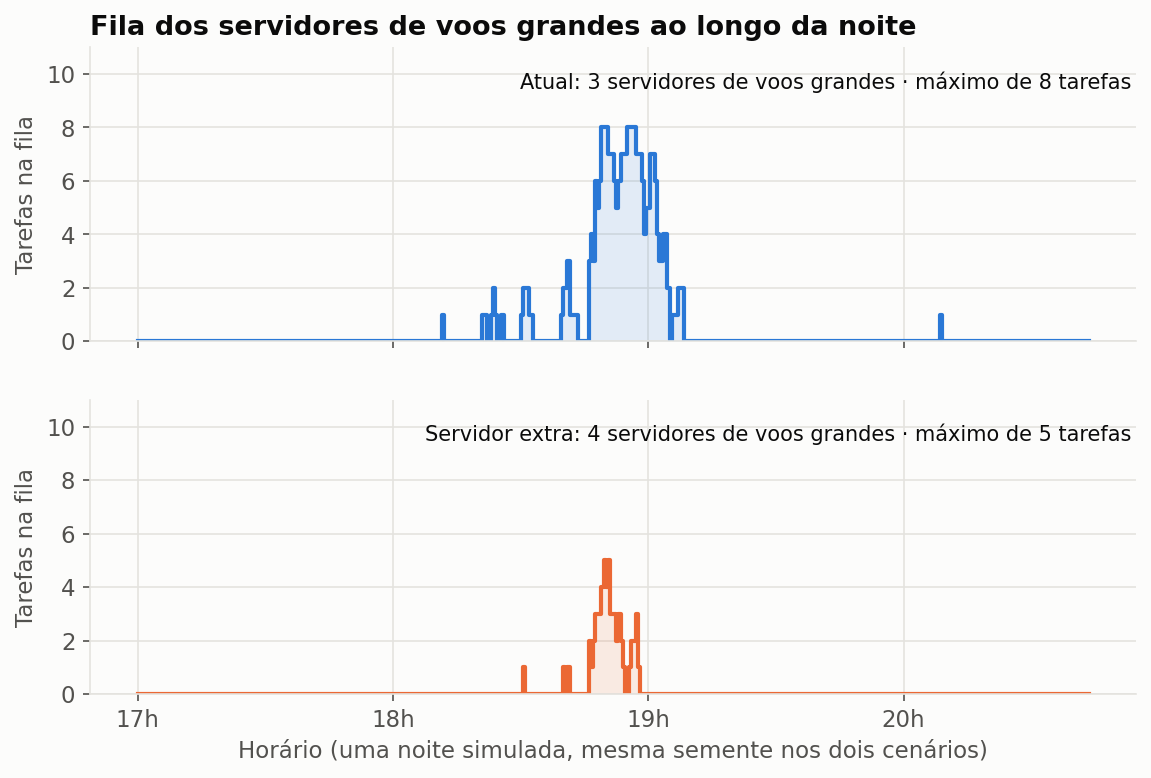

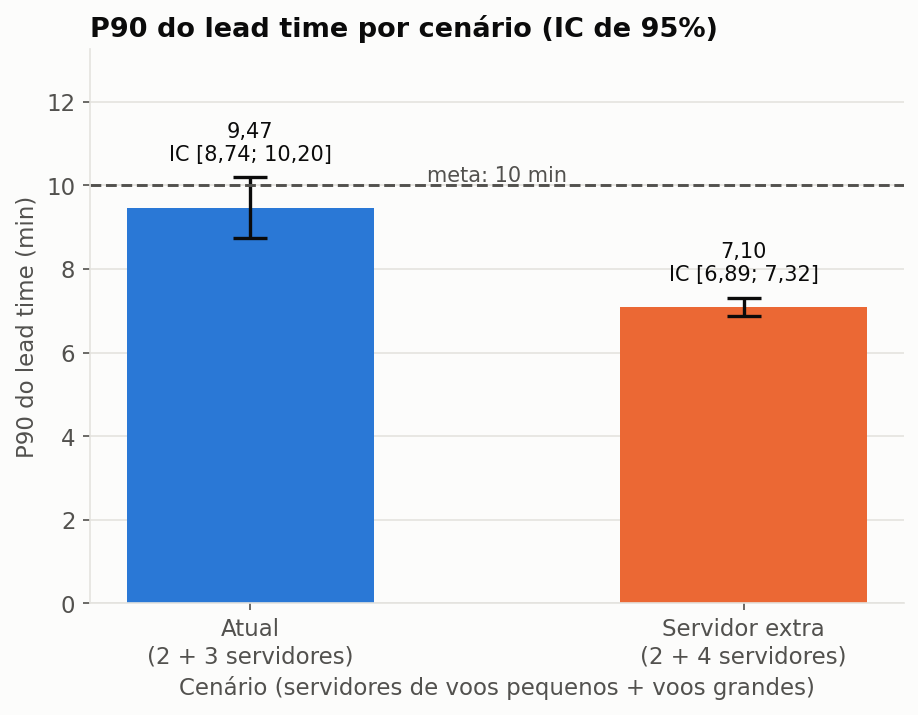

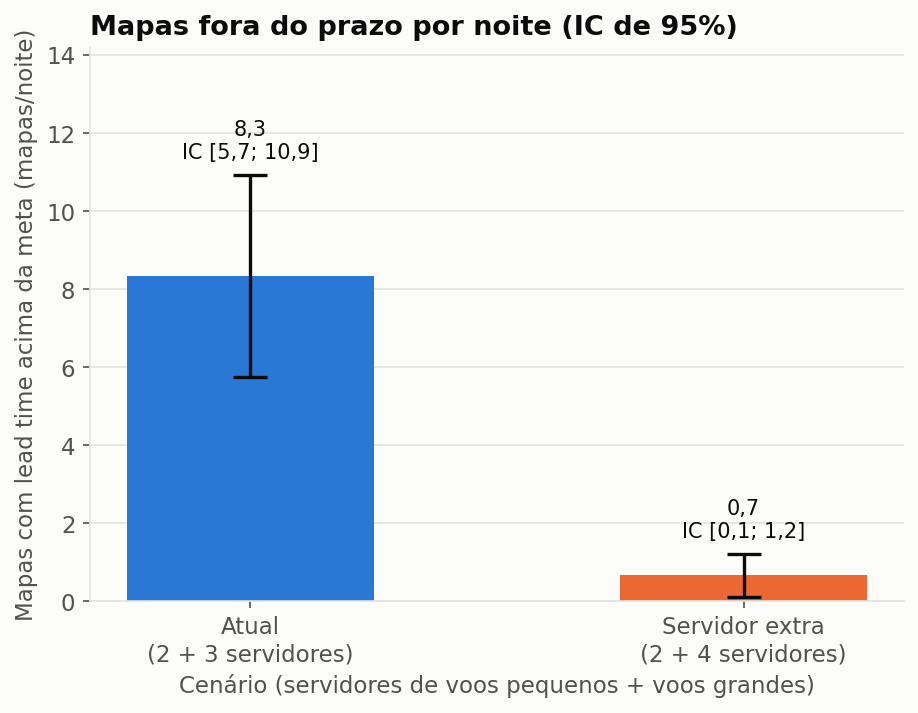

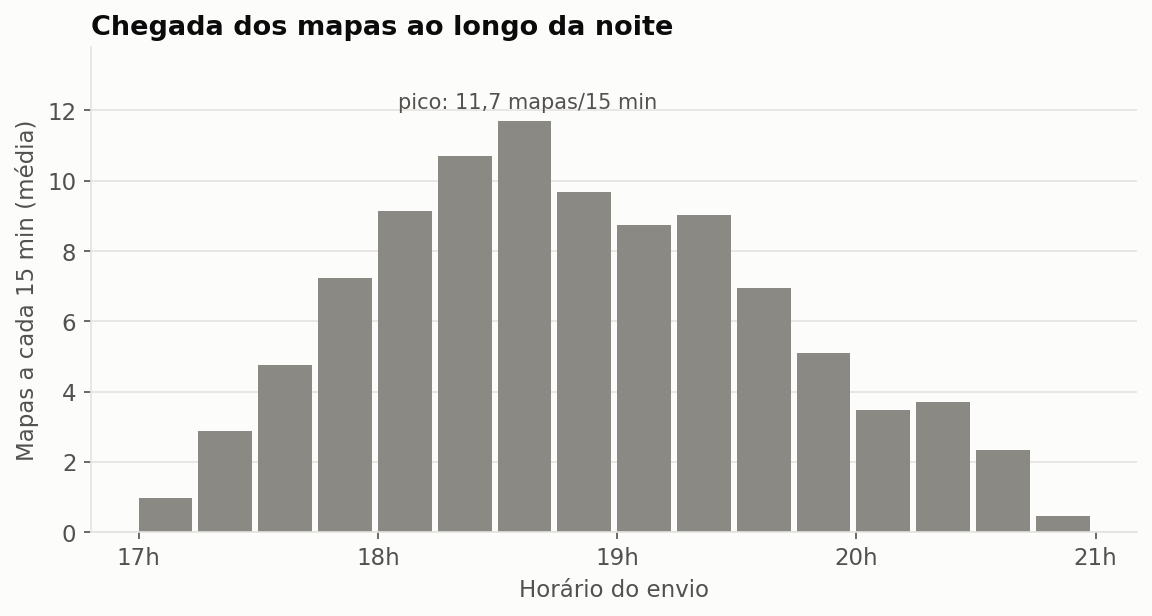

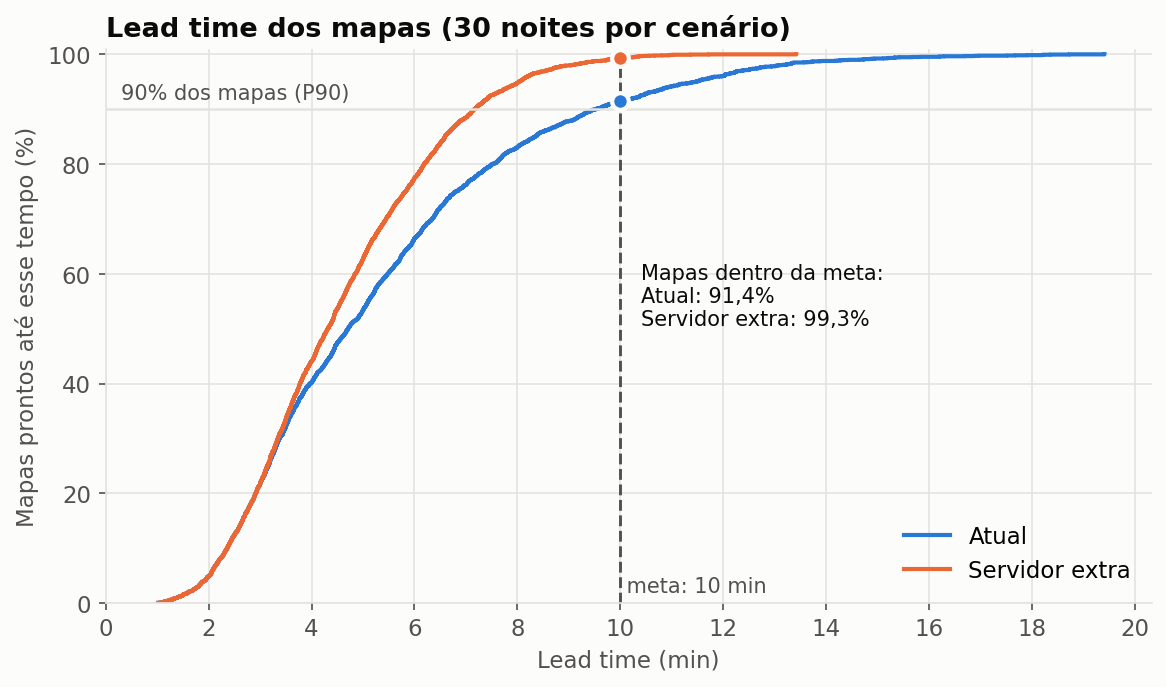

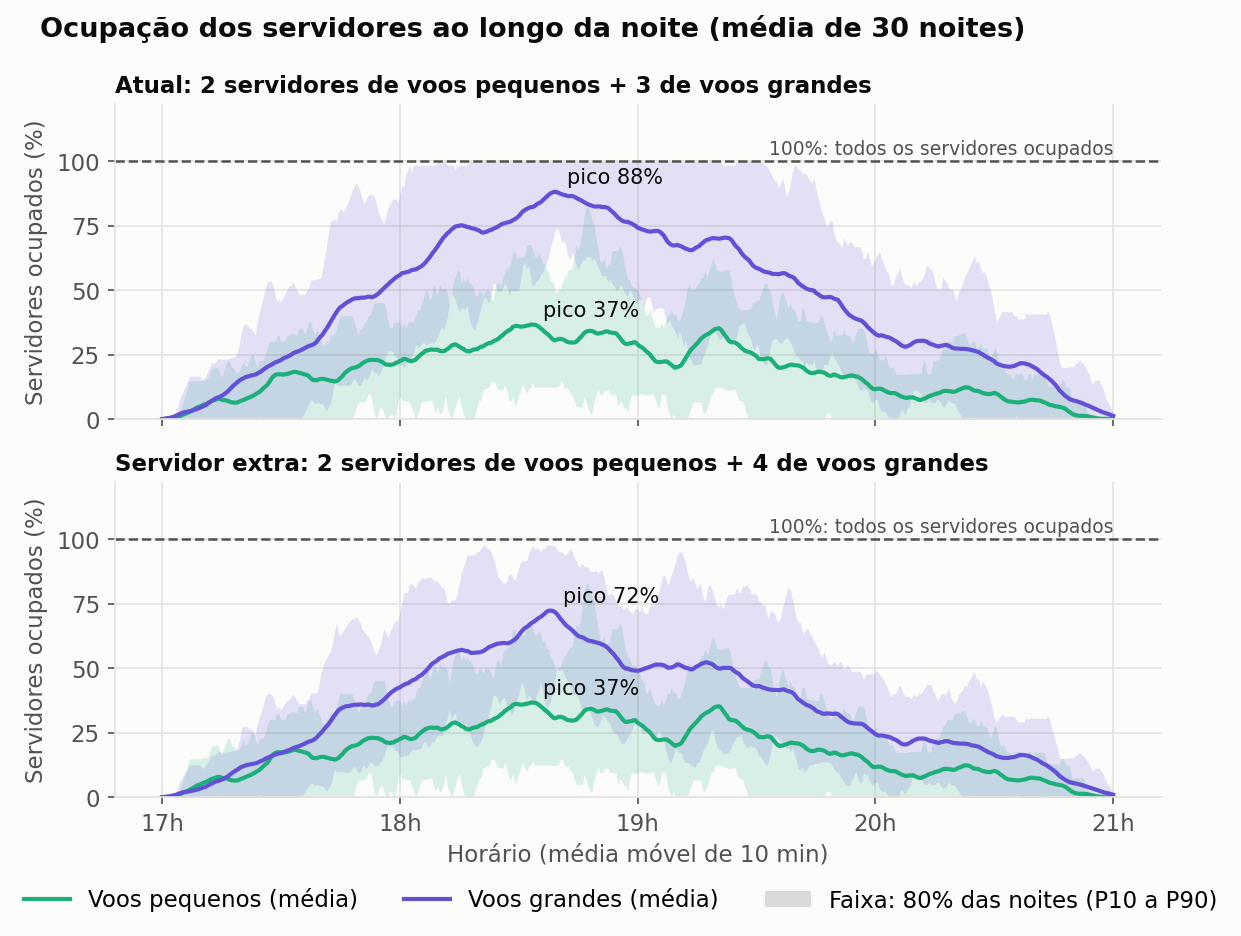

In [5]:
CORES = {"Atual": "#2a78d6", "Servidor extra": "#eb6834"}
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_SECUNDARIO = "#52514e"
GRADE = "#e4e3df"
NEUTRO = "#8a8984"
VERDE = "#1baf7a"
ROXO = "#6250d6"
INTERVALO_CHEGADAS = 15

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SECUNDARIO,
    "axes.titlecolor": TEXTO,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SECUNDARIO,
    "ytick.color": TEXTO_SECUNDARIO,
    "legend.frameon": False,
    "font.size": 11,
})

os.makedirs(PASTA_GRAFICOS, exist_ok=True)


def rotulos_hora(eixo, fim_min):
    marcas = np.arange(0, fim_min + 1, 60)
    eixo.set_xticks(marcas)
    eixo.set_xticklabels([f"{HORA_INICIO + int(m // 60)}h" for m in marcas])


def br(texto):
    return texto.replace(".", ",")


def salvar_e_mostrar(figura, nome):
    caminho = os.path.join(PASTA_GRAFICOS, nome)
    figura.savefig(caminho, dpi=150, bbox_inches="tight")
    plt.show()


# 1. Fila dos servidores de voos grandes em degraus (Requisito 3g)
execucoes_ref = {c: executar_simulacao(c, SEMENTE_REFERENCIA) for c in CENARIOS}
fim_ref = max(amb.now for amb, _, _ in execucoes_ref.values())
fila_max_ref = max(a["fila_grandes"] for _, est, _ in execucoes_ref.values() for a in est.amostras)

figura, eixos = plt.subplots(len(CENARIOS), 1, figsize=(9, 5.6), sharex=True, sharey=True)
for eixo, (cenario, (ambiente, estatisticas, capacidades)) in zip(eixos, execucoes_ref.items()):
    tempos = [a["tempo"] for a in estatisticas.amostras]
    fila = [a["fila_grandes"] for a in estatisticas.amostras]
    eixo.step(tempos, fila, where="post", color=CORES[cenario], linewidth=2)
    eixo.fill_between(tempos, fila, step="post", color=CORES[cenario], alpha=0.12, linewidth=0)
    eixo.text(0.995, 0.92,
              f"{cenario}: {capacidades['servidores_grandes']} servidores de voos grandes · máximo de {max(fila)} tarefas",
              transform=eixo.transAxes, ha="right", va="top", color=TEXTO, fontsize=10)
    eixo.set_ylabel("Tarefas na fila")
    eixo.set_ylim(0, fila_max_ref * 1.25 + 1)
eixos[0].set_title("Fila dos servidores de voos grandes ao longo da noite")
eixos[-1].set_xlabel("Horário (uma noite simulada, mesma semente nos dois cenários)")
rotulos_hora(eixos[-1], fim_ref)
salvar_e_mostrar(figura, "fila_voos_grandes.png")


# 2. Comparação de cenários com barras de erro do IC de 95% (Requisito 3g)
def grafico_ic(resumo, chave, titulo, rotulo_y, nome, meta=None, rotulo_meta=None, formato="{:.2f}"):
    cenarios = list(resumo)
    medias = [resumo[c][chave][0] for c in cenarios]
    meias = [resumo[c][chave][2] for c in cenarios]
    posicoes = np.arange(len(cenarios))

    figura, eixo = plt.subplots(figsize=(7, 4.8))
    eixo.bar(posicoes, medias, width=0.5, color=[CORES[c] for c in cenarios])
    eixo.errorbar(posicoes, medias, yerr=meias, fmt="none", ecolor=TEXTO, elinewidth=1.6, capsize=8, capthick=1.6)
    for x, m, h in zip(posicoes, medias, meias):
        eixo.annotate(br(f"{formato.format(m)}\nIC [{formato.format(m - h)}; {formato.format(m + h)}]"),
                      xy=(x, m + h), xytext=(0, 6), textcoords="offset points",
                      ha="center", va="bottom", color=TEXTO, fontsize=10)
    topo = max(m + h for m, h in zip(medias, meias))
    if meta is not None:
        eixo.axhline(meta, color=TEXTO_SECUNDARIO, linestyle="--", linewidth=1.4)
        eixo.text((posicoes[0] + posicoes[-1]) / 2, meta, rotulo_meta, ha="center", va="bottom",
                  color=TEXTO_SECUNDARIO, fontsize=10)
        topo = max(topo, meta)
    eixo.set_ylim(0, topo * 1.3)
    eixo.set_xticks(posicoes)
    eixo.set_xticklabels([f"{c}\n({CENARIOS[c]['servidores_pequenos']} + {CENARIOS[c]['servidores_grandes']} servidores)"
                          for c in cenarios])
    eixo.set_xlabel("Cenário (servidores de voos pequenos + voos grandes)")
    eixo.set_ylabel(rotulo_y)
    eixo.set_title(titulo)
    eixo.grid(axis="x", visible=False)
    salvar_e_mostrar(figura, nome)


grafico_ic(resumo_30, "p90_lead_time_min", "P90 do lead time por cenário (IC de 95%)",
           "P90 do lead time (min)", "p90_lead_time_ic.png",
           meta=META_LEAD_TIME, rotulo_meta=f"meta: {META_LEAD_TIME:.0f} min")

grafico_ic(resumo_30, "mapas_fora_prazo", "Mapas fora do prazo por noite (IC de 95%)",
           "Mapas com lead time acima da meta (mapas/noite)", "mapas_fora_prazo_ic.png",
           formato="{:.1f}")

# 3. Chegada dos mapas ao longo da noite (a cada 15 min)
bordas = np.arange(0, ENVIO_MAX + INTERVALO_CHEGADAS, INTERVALO_CHEGADAS)
contagens = np.array([np.histogram([m.instante_entrada for m in gerar_mapas(s)], bins=bordas)[0] for s in SEMENTES])
media_cheg = contagens.mean(axis=0)
figura, eixo = plt.subplots(figsize=(9, 4.2))
eixo.bar(bordas[:-1], media_cheg, width=INTERVALO_CHEGADAS - 1.5, align="edge", color=NEUTRO)
eixo.set_title("Chegada dos mapas ao longo da noite")
eixo.set_xlabel("Horário do envio")
eixo.set_ylabel(f"Mapas a cada {INTERVALO_CHEGADAS} min (média)")
eixo.grid(axis="x", visible=False)
rotulos_hora(eixo, ENVIO_MAX)
pico = bordas[np.argmax(media_cheg)]
eixo.annotate(br(f"pico: {media_cheg.max():.1f} mapas/{INTERVALO_CHEGADAS} min"),
              xy=(pico + INTERVALO_CHEGADAS / 2, media_cheg.max()), xytext=(0, 6),
              textcoords="offset points", ha="center", color=TEXTO_SECUNDARIO, fontsize=10)
eixo.set_ylim(0, media_cheg.max() * 1.18)
salvar_e_mostrar(figura, "chegadas_por_intervalo.png")

# 4. Curva acumulada do lead time (30 noites por cenário)
figura, eixo = plt.subplots(figsize=(9, 4.8))
resumo_meta = []
for cenario in CENARIOS:
    leads = []
    for semente in SEMENTES:
        _, estatisticas, _ = executar_simulacao(cenario, semente)
        leads.extend(m.lead_time for m in estatisticas.mapas)
    leads = np.sort(leads)
    proporcao = np.arange(1, len(leads) + 1) / len(leads)
    eixo.step(leads, proporcao * 100, where="post", color=CORES[cenario], linewidth=2, label=cenario)
    dentro = np.mean(leads <= META_LEAD_TIME) * 100
    eixo.plot([META_LEAD_TIME], [dentro], "o", markersize=8, color=CORES[cenario],
              markeredgecolor=SUPERFICIE, markeredgewidth=2, zorder=5)
    resumo_meta.append(br(f"{cenario}: {dentro:.1f}%"))
eixo.axvline(META_LEAD_TIME, color=TEXTO_SECUNDARIO, linestyle="--", linewidth=1.4)
eixo.text(META_LEAD_TIME + 0.4, 62, "Mapas dentro da meta:\n" + "\n".join(resumo_meta),
          color=TEXTO, fontsize=10, va="top")
eixo.set_xticks(np.arange(0, 22, 2))
eixo.axhline(90, color=GRADE, linewidth=1.2)
eixo.text(0.3, 91, "90% dos mapas (P90)", color=TEXTO_SECUNDARIO, fontsize=10, va="bottom")
eixo.text(META_LEAD_TIME, 2, f" meta: {META_LEAD_TIME:.0f} min", color=TEXTO_SECUNDARIO, fontsize=10)
eixo.set_title(f"Lead time dos mapas ({len(SEMENTES)} noites por cenário)")
eixo.set_xlabel("Lead time (min)")
eixo.set_ylabel("Mapas prontos até esse tempo (%)")
eixo.set_ylim(0, 101)
eixo.set_xlim(0, None)
eixo.legend(loc="lower right")
salvar_e_mostrar(figura, "distribuicao_lead_time.png")

# 5. Ocupação dos servidores ao longo da noite (média de 30 noites e faixa P10–P90)
grupos_ocup = [("pequenos", "Voos pequenos", VERDE), ("grandes", "Voos grandes", ROXO)]
janela = int(10 / INTERVALO_MONITOR)
series = {}
for cenario, capacidades in CENARIOS.items():
    execucoes = [executar_simulacao(cenario, s)[1].amostras for s in SEMENTES]
    n = max(len(a) for a in execucoes)
    series[cenario] = {}
    for chave, _, _ in grupos_ocup:
        capacidade = capacidades[f"servidores_{chave}"]
        matriz = np.zeros((len(execucoes), n))
        for i, amostras in enumerate(execucoes):
            matriz[i, :len(amostras)] = [a[f"ocupados_{chave}"] / capacidade for a in amostras]
        suavizada = np.array([np.convolve(linha, np.ones(janela) / janela, mode="same") for linha in matriz]) * 100
        series[cenario][chave] = suavizada.mean(axis=0)
        series[cenario][f"{chave}_p10"] = np.percentile(suavizada, 10, axis=0)
        series[cenario][f"{chave}_p90"] = np.percentile(suavizada, 90, axis=0)
    series[cenario]["tempo"] = np.arange(n) * INTERVALO_MONITOR

fim_ocup = max(s["tempo"][-1] for s in series.values())
figura, eixos = plt.subplots(len(CENARIOS), 1, figsize=(9, 6), sharex=True, sharey=True)
for eixo, (cenario, capacidades) in zip(eixos, CENARIOS.items()):
    dados = series[cenario]
    for chave, nome, cor in grupos_ocup:
        pico = dados[chave].max()
        eixo.fill_between(dados["tempo"], dados[f"{chave}_p10"], dados[f"{chave}_p90"], color=cor, alpha=0.16, linewidth=0)
        eixo.plot(dados["tempo"], dados[chave], color=cor, linewidth=2, label=f"{nome} (média)")
        momento = dados["tempo"][np.argmax(dados[chave])]
        eixo.annotate(br(f"pico {pico:.0f}%"), xy=(momento, pico), xytext=(6, 4), textcoords="offset points", color=TEXTO, fontsize=10)
    eixo.axhline(100, color=TEXTO_SECUNDARIO, linestyle="--", linewidth=1.2)
    eixo.text(fim_ocup, 101, "100%: todos os servidores ocupados", ha="right", va="bottom", color=TEXTO_SECUNDARIO, fontsize=9)
    eixo.set_title(f"{cenario}: {capacidades['servidores_pequenos']} servidores de voos pequenos + {capacidades['servidores_grandes']} de voos grandes", fontsize=11)
    eixo.set_ylabel("Servidores ocupados (%)")
    eixo.set_ylim(0, 122)
figura.suptitle(f"Ocupação dos servidores ao longo da noite (média de {len(SEMENTES)} noites)", x=0.07, ha="left", fontsize=13, weight="bold", color=TEXTO)
alcas, rotulos = eixos[0].get_legend_handles_labels()
alcas.append(Patch(facecolor=NEUTRO, alpha=0.3, linewidth=0))
rotulos.append("Faixa: 80% das noites (P10 a P90)")
figura.legend(alcas, rotulos, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
eixos[-1].set_xlabel("Horário (média móvel de 10 min)")
rotulos_hora(eixos[-1], fim_ocup)
salvar_e_mostrar(figura, "ocupacao_servidores.png")

## 5. Demonstração Visual do Modelo em Execução (`FuncAnimation` → MP4)

Atende ao **requisito 3f** e à **Seção 4** do enunciado:
* **Título do cenário** e **relógio da simulação** (`17h00` até a conclusão do último mapa);
* **Quatro indicadores em texto, cada um com sua unidade** (`tarefas`, `%`, `mapas`);
* **Esquema visual do sistema** exibindo o fluxo completo, as filas e os servidores ocupados/livres a cada instante;
* **Gráfico dinâmico com eixos rotulados** desenhando em degraus a evolução da fila de voos grandes ao longo da noite;
* Exportação direta para **`resultados/animacao_modelo.mp4`** (duração de ~33 segundos a 15 fps, dentro do limite de até 1 minuto).

In [6]:
def _buscar_ffmpeg():
    caminho = shutil.which("ffmpeg")
    if caminho:
        return caminho
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None


def preparar_quadros(cenario="Atual", semente=SEMENTE_REFERENCIA, passo=1):
    ambiente, estatisticas, capacidades = executar_simulacao(cenario, semente)
    amostras = list(estatisticas.amostras)
    mapas = estatisticas.mapas

    if not amostras or amostras[-1]["tempo"] < ambiente.now:
        amostras.append({
            "tempo": ambiente.now,
            "fila_cpu": 0,
            "fila_pequenos": 0,
            "fila_grandes": 0,
            "ocupados_pequenos": 0,
            "ocupados_grandes": 0,
            "concluidos": len(mapas),
        })

    quadros = []
    for idx in range(0, len(amostras), passo):
        a = dict(amostras[idx])
        t = a["tempo"]
        enviados = sum(1 for m in mapas if m.instante_entrada <= t)
        concluidos_ate_t = [m for m in mapas if m.instante_saida is not None and m.instante_saida <= t]
        fora_prazo_ate_t = sum(1 for m in concluidos_ate_t if m.lead_time > META_LEAD_TIME)
        reenvios_ate_t = sum(1 for m in mapas if m.instante_entrada <= t and m.tentativas > 1)
        em_cpu = 1 if any(
            m.instante_entrada <= t and (m.instante_saida is None or m.instante_saida > t)
            and abs(t - m.instante_entrada) < 0.35
            for m in mapas
        ) else 0

        a["indice_amostra"] = idx
        a["enviados"] = enviados
        a["fora_prazo"] = fora_prazo_ate_t
        a["reenvios"] = reenvios_ate_t
        a["ocupado_cpu"] = max(em_cpu, 1 if a["fila_cpu"] > 0 else 0)
        a["pct_ocup_grandes"] = 100.0 * a["ocupados_grandes"] / capacidades["servidores_grandes"]
        a["pct_ocup_pequenos"] = 100.0 * a["ocupados_pequenos"] / capacidades["servidores_pequenos"]
        quadros.append(a)

    return ambiente, estatisticas, capacidades, amostras, quadros


def gerar_animacao_mp4(
    cenario="Atual",
    semente=SEMENTE_REFERENCIA,
    passo=1,
    fps=15,
    caminho_saida=os.path.join(PASTA_RESULTADOS, "animacao_modelo.mp4"),
):
    ffmpeg_bin = _buscar_ffmpeg()
    if ffmpeg_bin:
        matplotlib.rcParams["animation.ffmpeg_path"] = ffmpeg_bin

    AZUL_C = "#2a78d6"
    LARANJA_C = "#eb6834"
    VERDE_C = "#1baf7a"
    ROXO_C = "#6250d6"

    ambiente, estatisticas, capacidades, amostras, quadros = preparar_quadros(cenario, semente, passo)
    cap_peq = capacidades["servidores_pequenos"]
    cap_grd = capacidades["servidores_grandes"]
    total_mapas = len(estatisticas.mapas)

    figura = plt.figure(figsize=(12.8, 7.2), dpi=100, facecolor=SUPERFICIE)

    # 1. Cabeçalho: título do cenário e relógio da simulação
    figura.text(
        0.035, 0.955,
        f"Cenário {cenario} · {cap_peq} servidores de voos pequenos + {cap_grd} de voos grandes",
        fontsize=13.5, fontweight="bold", color=TEXTO, va="center"
    )
    figura.text(
        0.035, 0.922,
        f"Plataforma de Processamento de Imagens de Drones · Noite de pico (meta de SLA: até {META_LEAD_TIME:.0f} min)",
        fontsize=10.0, color=TEXTO_SECUNDARIO, va="center"
    )
    txt_relogio = figura.text(
        0.965, 0.942, "",
        fontsize=13.0, fontweight="bold", family="monospace", color=TEXTO, ha="right", va="center",
        bbox=dict(boxstyle="round,pad=0.32,rounding_size=0.15", fc="#efeee9", ec=GRADE, lw=1.2)
    )

    # 2. Quatro indicadores vivos em texto com unidade
    cartoes_ind = [
        (0.035, 0.825, 0.22, 0.068, "Fila (voos grandes)", AZUL_C),
        (0.273, 0.825, 0.22, 0.068, "Ocupação (voos grandes)", ROXO_C),
        (0.511, 0.825, 0.22, 0.068, "Mapas concluídos", VERDE_C),
        (0.749, 0.825, 0.216, 0.068, f"Fora do prazo (> {META_LEAD_TIME:.0f} min)", LARANJA_C),
    ]
    textos_indicadores = []
    for x, y, w, h, rotulo, cor in cartoes_ind:
        ax_card = figura.add_axes([x, y, w, h])
        ax_card.set_xlim(0, 1); ax_card.set_ylim(0, 1); ax_card.axis("off")
        ax_card.add_patch(FancyBboxPatch((0.01, 0.04), 0.98, 0.92,
                                         boxstyle="round,pad=0.02,rounding_size=0.08", fc="white", ec=GRADE, lw=1.3))
        ax_card.plot([0.01, 0.01], [0.12, 0.88], color=cor, lw=4, solid_capstyle="round")
        ax_card.text(0.06, 0.72, rotulo, fontsize=9.5, color=TEXTO_SECUNDARIO, va="center")
        t_val = ax_card.text(0.06, 0.28, "", fontsize=13.5, fontweight="bold", color=cor, va="center")
        textos_indicadores.append(t_val)

    txt_fila_grd, txt_ocup_grd, txt_concluidos, txt_fora_prazo = textos_indicadores

    # 3. Cena esquemática do modelo
    cena = figura.add_axes([0.035, 0.39, 0.93, 0.415])
    cena.set_xlim(0, 18.0); cena.set_ylim(0, 6.4); cena.axis("off")

    def desenhar_caixa(x, y, w, h, titulo, subtitulo="", cor_borda=GRADE, cor_fundo="white", tamanho=10):
        patch = cena.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.14",
                                              fc=cor_fundo, ec=cor_borda, lw=1.6))
        if subtitulo:
            cena.text(x + w / 2, y + h * 0.64, titulo, ha="center", va="center", fontsize=tamanho, fontweight="bold", color=TEXTO)
            cena.text(x + w / 2, y + h * 0.30, subtitulo, ha="center", va="center", fontsize=8.5, color=TEXTO_SECUNDARIO)
        else:
            cena.text(x + w / 2, y + h / 2, titulo, ha="center", va="center", fontsize=tamanho, fontweight="bold", color=TEXTO)
        return patch

    def seta(x1, y1, x2, y2, cor=NEUTRO, estilo="->", tracejado=False):
        cena.annotate("", xy=(x2, y2), xytext=(x1, y1),
                      arrowprops=dict(arrowstyle=estilo, lw=1.6, color=cor,
                                      linestyle="--" if tracejado else "-", shrinkA=0, shrinkB=0))

    desenhar_caixa(0.1, 2.35, 1.9, 1.5, "Fim do Upload", "Entra o mapa", cor_borda=TEXTO_SECUNDARIO, cor_fundo="#f3f2ee")
    txt_enviados = cena.text(1.05, 2.0, "Enviados: 0 mapas", ha="center", va="top", fontsize=8.8, color=TEXTO_SECUNDARIO, fontweight="bold")
    seta(2.05, 3.1, 2.45, 3.1)

    box_cpu = desenhar_caixa(2.5, 2.35, 2.1, 1.5, "Validação · CPU (1)", "5 a 15 s | 5% falha", cor_borda=TEXTO_SECUNDARIO, cor_fundo="white")
    txt_reenvios = cena.text(3.55, 2.0, "Com reenvio: 0 mapas", ha="center", va="top", fontsize=8.6, color=TEXTO_SECUNDARIO)
    desenhar_caixa(2.45, 4.55, 2.2, 0.95, "Correção (Prestador)", "Faltou arquivo (1 a 3 min)", cor_borda=LARANJA_C, cor_fundo="#fdf3ee", tamanho=8.6)
    seta(4.0, 3.9, 4.0, 4.5, cor=LARANJA_C, tracejado=True)
    seta(3.1, 4.5, 3.1, 3.9, cor=LARANJA_C, tracejado=True)

    seta(4.65, 3.1, 5.05, 3.1)
    lx, ly = 5.85, 3.1
    cena.add_patch(Polygon([[lx - 0.78, ly], [lx, ly + 0.78], [lx + 0.78, ly], [lx, ly - 0.78]],
                           closed=True, fc="#fff9eb", ec="#d99b26", lw=1.6))
    cena.text(lx, ly + 0.14, "num_imagens", ha="center", va="center", fontsize=8.0, fontweight="bold", color=TEXTO)
    cena.text(lx, ly - 0.16, f"> {LIMITE_ROTA}?", ha="center", va="center", fontsize=8.3, fontweight="bold", color=TEXTO)

    cena.plot([lx, lx], [ly + 0.78, 4.85], color=VERDE_C, lw=1.6)
    seta(lx, 4.85, 7.55, 4.85, cor=VERDE_C)
    cena.text((lx + 7.55) / 2, 5.02, "não (≤ 80 img)", ha="center", fontsize=8.2, color=VERDE_C, fontweight="bold")

    cena.plot([lx, lx], [ly - 0.78, 1.55], color=AZUL_C, lw=1.6)
    seta(lx, 1.55, 7.55, 1.55, cor=AZUL_C)
    cena.text((lx + 7.55) / 2, 1.72, "sim (> 80 img)", ha="center", fontsize=8.2, color=AZUL_C, fontweight="bold")

    # Ramo Superior: Voos Pequenos
    cena.add_patch(FancyBboxPatch((7.6, 3.75), 7.55, 2.35, boxstyle="round,pad=0.04,rounding_size=0.16",
                                  fc="#eef8f4", ec=VERDE_C, lw=1.4, ls="--"))
    cena.text(11.375, 5.86, f"Voos Pequenos ({cap_peq} serv.) · Alinhamento → Ortomosaico // Elevação → Junção",
              ha="center", va="center", fontsize=8.3, fontweight="bold", color=VERDE_C)
    cena.add_patch(FancyBboxPatch((7.85, 4.2), 3.3, 1.15, boxstyle="round,pad=0.02,rounding_size=0.1", fc="white", ec=VERDE_C, lw=1.2))
    cena.text(9.5, 4.02, "Fila única FIFO (pequenos)", ha="center", va="top", fontsize=8.3, color=TEXTO_SECUNDARIO)
    max_bolas_peq = 6
    bolas_peq = [cena.add_patch(Circle((10.85 - i * 0.46, 4.78), 0.17, fc=VERDE_C, ec="white", lw=1.0, visible=False)) for i in range(max_bolas_peq)]
    txt_excesso_peq = cena.text(8.0, 4.78, "", ha="left", va="center", fontsize=8.5, fontweight="bold", color=VERDE_C)
    seta(11.2, 4.78, 11.75, 4.78, cor=VERDE_C)

    caixas_serv_peq, textos_serv_peq = [], []
    for k in range(cap_peq):
        y_s = 4.95 - k * 0.82
        p = FancyBboxPatch((11.8, y_s), 3.05, 0.66, boxstyle="round,pad=0.02,rounding_size=0.1", fc="white", ec=VERDE_C, lw=1.4)
        cena.add_patch(p)
        t_s = cena.text(13.325, y_s + 0.33, f"Servidor P{k + 1}: livre", ha="center", va="center", fontsize=8.8, fontweight="bold", color=TEXTO_SECUNDARIO)
        caixas_serv_peq.append(p); textos_serv_peq.append(t_s)

    # Ramo Inferior: Voos Grandes
    cena.add_patch(FancyBboxPatch((7.6, 0.25), 7.55, 2.95, boxstyle="round,pad=0.04,rounding_size=0.16",
                                  fc="#eef4fc", ec=AZUL_C, lw=1.6, ls="--"))
    cena.text(11.375, 2.96, f"Voos Grandes ({cap_grd} serv. · Gargalo) · Alinhamento → Ortomosaico // Elevação → Junção",
              ha="center", va="center", fontsize=8.3, fontweight="bold", color=AZUL_C)
    cena.add_patch(FancyBboxPatch((7.85, 0.95), 3.3, 1.35, boxstyle="round,pad=0.02,rounding_size=0.1", fc="white", ec=AZUL_C, lw=1.3))
    cena.text(9.5, 0.76, "Fila única FIFO (grandes)", ha="center", va="top", fontsize=8.3, color=TEXTO_SECUNDARIO)
    max_bolas_grd = 8
    pos_bolas_grd = [(10.85 - (i % 4) * 0.58, 1.88 if i < 4 else 1.35) for i in range(max_bolas_grd)]
    bolas_grd = [cena.add_patch(Circle(pos, 0.18, fc=AZUL_C, ec="white", lw=1.0, visible=False)) for pos in pos_bolas_grd]
    txt_excesso_grd = cena.text(8.0, 1.62, "", ha="left", va="center", fontsize=9, fontweight="bold", color=LARANJA_C)
    seta(11.2, 1.62, 11.75, 1.62, cor=AZUL_C)

    caixas_serv_grd, textos_serv_grd = [], []
    altura_disp = 2.25
    passo_y = altura_disp / cap_grd
    altura_caixa = min(0.58, passo_y - 0.12)
    y_topo_grd = 2.15
    for k in range(cap_grd):
        y_s = y_topo_grd - k * passo_y
        p = FancyBboxPatch((11.8, y_s), 3.05, altura_caixa, boxstyle="round,pad=0.02,rounding_size=0.1", fc="white", ec=AZUL_C, lw=1.4)
        cena.add_patch(p)
        t_s = cena.text(13.325, y_s + altura_caixa / 2, f"Servidor G{k + 1}: livre", ha="center", va="center", fontsize=8.6, fontweight="bold", color=TEXTO_SECUNDARIO)
        caixas_serv_grd.append(p); textos_serv_grd.append(t_s)

    cena.plot([15.15, 15.65], [4.85, 3.45], color=VERDE_C, lw=1.6)
    cena.plot([15.15, 15.65], [1.55, 2.75], color=AZUL_C, lw=1.6)
    seta(15.65, 3.1, 15.95, 3.1, cor=TEXTO_SECUNDARIO)
    desenhar_caixa(16.0, 2.25, 1.8, 1.7, "Mapa Pronto", "Notificação", cor_borda=VERDE_C, cor_fundo="#eef8f4")

    # 4. Gráfico em degraus na parte inferior
    graf = figura.add_axes([0.075, 0.085, 0.89, 0.255])
    graf.set_facecolor("white")
    tempos_todos = [a["tempo"] for a in amostras]
    filas_todas = [a["fila_grandes"] for a in amostras]
    fim_min = max(245.0, max(tempos_todos))
    fila_max = max(8, max(filas_todas))

    graf.set_xlim(0, fim_min); graf.set_ylim(0, fila_max + 2)
    marcas_x = np.arange(0, fim_min + 1, 30)
    graf.set_xticks(marcas_x)
    graf.set_xticklabels([formatar_hora(m) for m in marcas_x], fontsize=9.5, color=TEXTO_SECUNDARIO)
    graf.set_yticks(np.arange(0, fila_max + 3, 2))
    graf.tick_params(axis="y", labelsize=9.5, colors=TEXTO_SECUNDARIO)
    graf.spines["top"].set_visible(False); graf.spines["right"].set_visible(False)
    graf.spines["left"].set_color(GRADE); graf.spines["bottom"].set_color(GRADE)
    graf.grid(True, color=GRADE, lw=0.8)
    graf.set_title("Evolução temporal da fila dos servidores de voos grandes (em degraus)",
                   loc="left", fontsize=11.5, fontweight="bold", color=TEXTO, pad=6)
    graf.set_xlabel("Horário da noite (tempo simulado, em horas)", fontsize=10, color=TEXTO_SECUNDARIO)
    graf.set_ylabel("Tarefas na fila (tarefas)", fontsize=10, color=TEXTO_SECUNDARIO)

    (linha_step,) = graf.step([], [], where="post", color=AZUL_C, lw=2.0)
    (ponto_atual,) = graf.plot([], [], "o", color=LARANJA_C, markersize=6.5, zorder=5)

    def atualizar_quadro(i):
        q = quadros[i]
        t = q["tempo"]
        n_amostra = q["indice_amostra"] + 1

        txt_relogio.set_text(f"Horário: {formatar_hora(t)}  (t = {t:5.1f} min)".replace(".", ","))
        txt_fila_grd.set_text(f"{q['fila_grandes']} tarefas")
        txt_ocup_grd.set_text(f"{q['pct_ocup_grandes']:.0f}% ({q['ocupados_grandes']}/{cap_grd} serv.)")
        txt_concluidos.set_text(f"{q['concluidos']} / {total_mapas} mapas")
        txt_fora_prazo.set_text(f"{q['fora_prazo']} mapas")

        txt_enviados.set_text(f"Enviados: {q['enviados']} mapas")
        txt_reenvios.set_text(f"Com reenvio: {q['reenvios']} mapas")
        box_cpu.set_facecolor("#fff3e6" if q["ocupado_cpu"] else "white")

        for j, bola in enumerate(bolas_peq):
            bola.set_visible(j < q["fila_pequenos"])
        txt_excesso_peq.set_text(f"+{q['fila_pequenos'] - max_bolas_peq}" if q["fila_pequenos"] > max_bolas_peq else "")
        for k, (caixa_s, txt_s) in enumerate(zip(caixas_serv_peq, textos_serv_peq)):
            ocupado = k < q["ocupados_pequenos"]
            caixa_s.set_facecolor(VERDE_C if ocupado else "white")
            txt_s.set_text(f"Servidor P{k + 1}: ocupado" if ocupado else f"Servidor P{k + 1}: livre")
            txt_s.set_color("white" if ocupado else TEXTO_SECUNDARIO)

        lotado = q["ocupados_grandes"] == cap_grd and q["fila_grandes"] > 0
        cor_serv_grd = LARANJA_C if lotado else AZUL_C
        for j, bola in enumerate(bolas_grd):
            bola.set_visible(j < q["fila_grandes"])
            bola.set_facecolor(LARANJA_C if q["fila_grandes"] >= 4 else AZUL_C)
        txt_excesso_grd.set_text(f"+{q['fila_grandes'] - max_bolas_grd}" if q["fila_grandes"] > max_bolas_grd else "")
        for k, (caixa_s, txt_s) in enumerate(zip(caixas_serv_grd, textos_serv_grd)):
            ocupado = k < q["ocupados_grandes"]
            caixa_s.set_facecolor(cor_serv_grd if ocupado else "white")
            caixa_s.set_edgecolor(cor_serv_grd if ocupado else AZUL_C)
            txt_s.set_text(f"Servidor G{k + 1}: ocupado" if ocupado else f"Servidor G{k + 1}: livre")
            txt_s.set_color("white" if ocupado else TEXTO_SECUNDARIO)

        linha_step.set_data(tempos_todos[:n_amostra], filas_todas[:n_amostra])
        ponto_atual.set_data([t], [q["fila_grandes"]])
        return []

    os.makedirs(os.path.dirname(os.path.abspath(caminho_saida)), exist_ok=True)
    anim = animation.FuncAnimation(figura, atualizar_quadro, frames=len(quadros), interval=1000 / fps)

    if animation.writers.is_available("ffmpeg"):
        caminho_tmp = caminho_saida + ".raw.mp4"
        escritor = animation.FFMpegWriter(
            fps=fps,
            codec="libx264",
            bitrate=2000,
            extra_args=["-pix_fmt", "yuv420p"],
        )
        anim.save(caminho_tmp, writer=escritor)
        plt.close(figura)
        subprocess.run(
            [
                ffmpeg_bin or "ffmpeg", "-y",
                "-f", "lavfi", "-i", "anullsrc=channel_layout=stereo:sample_rate=44100",
                "-i", caminho_tmp,
                "-c:v", "libx264", "-profile:v", "main", "-pix_fmt", "yuv420p",
                "-c:a", "aac", "-b:a", "64k", "-shortest", "-movflags", "+faststart",
                caminho_saida,
            ],
            check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
        )
        if os.path.exists(caminho_tmp):
            os.remove(caminho_tmp)
        video_b64 = base64.b64encode(open(caminho_saida, "rb").read()).decode()
        display(HTML(f'<video width="960" controls autoplay loop muted>'
                     f'<source src="data:video/mp4;base64,{video_b64}" type="video/mp4"></video>'))
        print(f"Vídeo gravado em {caminho_saida}: {len(quadros)} quadros ({len(quadros) / fps:.1f} s a {fps} fps)")
    else:
        plt.close(figura)
        display(HTML(anim.to_jshtml(default_mode="once")))


gerar_animacao_mp4()

Vídeo gravado em resultados/animacao_modelo.mp4: 449 quadros (29.9 s a 15 fps)


## 6. Conclusões e Recomendações Fundamentadas no IC de 95%

1. **O cenário atual atende à meta de 10 min no pico?**
   * **Inconclusivo (opera no limite):** O P90 médio do *lead time* no Cenário Atual (2 + 3 servidores) é de **$9{,}47\text{ min}$**, porém o seu Intervalo de Confiança de 95% é **$[8{,}74;\, 10{,}20]\text{ min}$**, que contém o limite da meta de $10\text{ min}$. Além disso, em média **$8{,}3\text{ mapas/noite}$** ($8{,}5\%$, $\text{IC } [5{,}9\%;\, 11{,}0\%]$) ficam fora do prazo.
2. **Um servidor a mais no grupo de voos grandes reduz o P90 do *lead time* de forma conclusiva?**
   * **Sim:** Com 1 servidor extra no grupo de voos grandes (2 + 4 servidores), o P90 do *lead time* cai **$2{,}37\text{ min}$** (redução de $25\%$), passando de **$9{,}47\text{ min}$** ($\text{IC } [8{,}74;\, 10{,}20]\text{ min}$) para **$7{,}10\text{ min}$** ($\text{IC } [6{,}89;\, 7{,}32]\text{ min}$). Como os intervalos $[8{,}74;\, 10{,}20]$ e $[6{,}89;\, 7{,}32]$ **não se sobrepõem**, a diferença é estatisticamente conclusiva a 95% de confiança, e o IC inteiro passa a ficar com folga abaixo da meta de $10\text{ min}$.
3. **Quantos mapas deixam de atrasar por noite?**
   * Os mapas fora do prazo caem em **$7{,}6\text{ mapas/noite}$** (de **$8{,}3\text{ mapas/noite}$**, $\text{IC } [5{,}7;\, 10{,}9]$, para **$0{,}7\text{ mapas/noite}$**, $\text{IC } [0{,}1;\, 1{,}2]$), elevando a proporção de entregas no prazo de **$91{,}5\%$** para **$99{,}3\%$**.
4. **Recomendação de Gestão:**
   * Recomenda-se alocar **1 servidor adicional no grupo de voos grandes** (passando de 3 para 4 servidores), preferencialmente sob demanda (auto-scaling em nuvem) na janela crítica entre **17h45 e 20h00**, período em que a ocupação média do grupo atinge $88\%$ no cenário atual.